# Bitly Data from 1.USA.gov

- Vào năm 2011, dịch vụ rút gọn URL Bitly đã hợp tác với trang web của chính phủ Hoa Kỳ – USA.gov để cung cấp một nguồn dữ liệu ẩn danh được thu thập từ người dùng khi họ rút gọn các liên kết có đuôi .gov hoặc .mil.

- Trong năm đó, luồng dữ liệu trực tiếp (live feed) cùng với các bản chụp dữ liệu theo giờ (hourly snapshots) đều được công bố công khai dưới dạng tệp văn bản có thể tải xuống.

- Hiện tại (tính đến năm 2022), dịch vụ này đã ngừng hoạt động, nhưng một trong các tệp dữ liệu gốc đã được lưu giữ lại để sử dụng làm ví dụ trong cuốn sách này.

- Phân tích này nhằm:
    + Hiểu hành vi người dùng khi truy cập các trang chính phủ Mỹ (địa lý, thời gian, thiết bị);
    + Xác định phân bố người dùng theo múi giờ, hệ điều hành, quốc gia;
    + Quy trình phân tích dữ liệu JSON thực tế bằng Python/pandas: đọc – làm sạch – tổng hợp – trực quan hóa.

In [1]:

from numpy.random import randn
import numpy as np
np.random.seed(123)
import os
import matplotlib.pyplot as plt
import pandas as pd
plt.rc("figure", figsize=(10, 6))
np.set_printoptions(precision=4)
pd.options.display.max_columns = 20
pd.options.display.max_rows = 20
pd.options.display.max_colwidth = 80

In [2]:
path = "datasets/bitly_usagov/example.txt"

- Trong trường hợp các bản chụp dữ liệu theo giờ (hourly snapshots), mỗi dòng trong mỗi tệp chứa một dạng dữ liệu web phổ biến được gọi là JSON (JavaScript Object Notation).

- Ví dụ, nếu chúng ta đọc dòng đầu tiên của một tệp, ta có thể thấy một cấu trúc dữ liệu tương tự như sau:

In [3]:
with open(path) as f:
    print(f.readline())

{ "a": "Mozilla\/5.0 (Windows NT 6.1; WOW64) AppleWebKit\/535.11 (KHTML, like Gecko) Chrome\/17.0.963.78 Safari\/535.11", "c": "US", "nk": 1, "tz": "America\/New_York", "gr": "MA", "g": "A6qOVH", "h": "wfLQtf", "l": "orofrog", "al": "en-US,en;q=0.8", "hh": "1.usa.gov", "r": "http:\/\/www.facebook.com\/l\/7AQEFzjSi\/1.usa.gov\/wfLQtf", "u": "http:\/\/www.ncbi.nlm.nih.gov\/pubmed\/22415991", "t": 1331923247, "hc": 1331822918, "cy": "Danvers", "ll": [ 42.576698, -70.954903 ] }



- **Chú thích ý nghĩa của từng key**:
    - a - **Agent**: Chuỗi User-Agent: mô tả trình duyệt, hệ điều hành, thiết bị người dùng đang sử dụng.
    - c - **Country code**: Mã quốc gia (theo chuẩn ISO, ví dụ US = Mỹ, BR = Brazil, HK = Hong Kong).
    - nk - **Number of clicks**: Số lần người dùng click vào link đó (thường 0 hoặc 1).
    - tz - **Time zone**: Múi giờ người dùng, ví dụ America/New_York, Asia/Hong_Kong.
    - gr - **Region/State code**: Mã bang hoặc vùng (ví dụ MA = Massachusetts, CA = California).
    - g - **Global hash (short link ID)**: Mã rút gọn chính của liên kết (ví dụ A6qOVH).
    - h - **Hash (original short link ID)**: Hash ID khác hoặc mã rút gọn gốc tương ứng (thường dùng nội bộ để phân biệt loại link).
    - l - **Login**: Tên tài khoản người tạo link (login name của người tạo trên Bitly/USA.gov).
    - al - **Accept-Language**: Ngôn ngữ và mức ưu tiên của trình duyệt (ví dụ en-US,en;q=0.8).
    - hh - **Host header/short domain**: Tên host (thường là 1.usa.gov, bit.ly, hoặc j.mp).
    - r - **Referrer**: Referrer URL — trang web nơi người dùng nhấn vào liên kết (ví dụ Facebook, Twitter, t.co, hoặc “direct” nếu không có nguồn).
    - u - **URL (long link)**: URL đích thực tế mà link rút gọn trỏ đến (ví dụ một trang NASA, chính phủ,...).
    - t - **Timestamp (click time)**: Thời gian (timestamp UNIX) của lần click.
    - hc - **Hash creation time**: Thời gian (timestamp UNIX) của lần tạo link.
    - cy - **City**: Thành phố người dùng truy cập.
    - ll - **Latitude and Longitude**: Tọa độ địa lý [vĩ độ, kinh độ] của người dùng.
    - kw(_thỉnh thoảng xuất hiện_) - **Keyword**: Từ khóa được gắn với link.
    - heartbeat - **System heartbeat**: Bản ghi hệ thống tự động, chỉ để giữ kết nối “tim sống”, không chứa dữ liệu người dùng thực.

- Python có sẵn cả thư viện tích hợp (built-in) và thư viện của bên thứ ba (third-party) để chuyển đổi một chuỗi JSON (JSON string) thành từ điển (dictionary) trong Python.

- Trong ví dụ này, ta sẽ sử dụng mô-đun json có sẵn trong Python, cùng với hàm loads(), để đọc và chuyển đổi từng dòng trong tệp dữ liệu mẫu mà chúng ta đã tải về.

In [4]:
import json
with open(path) as f:
    records = [json.loads(line) for line in f]

Kết quả [dữ liệu ở dạng JSON]

In [5]:
records[0] # xem dòng đầu tiên trong tệp dữ liệu

{'a': 'Mozilla/5.0 (Windows NT 6.1; WOW64) AppleWebKit/535.11 (KHTML, like Gecko) Chrome/17.0.963.78 Safari/535.11',
 'c': 'US',
 'nk': 1,
 'tz': 'America/New_York',
 'gr': 'MA',
 'g': 'A6qOVH',
 'h': 'wfLQtf',
 'l': 'orofrog',
 'al': 'en-US,en;q=0.8',
 'hh': '1.usa.gov',
 'r': 'http://www.facebook.com/l/7AQEFzjSi/1.usa.gov/wfLQtf',
 'u': 'http://www.ncbi.nlm.nih.gov/pubmed/22415991',
 't': 1331923247,
 'hc': 1331822918,
 'cy': 'Danvers',
 'll': [42.576698, -70.954903]}

## Counting Time Zones in Pure Python

- Giả sử chúng ta muốn tìm ra các múi giờ (time zones) xuất hiện thường xuyên nhất trong tập dữ liệu — tức là trường tz (time zone) trong mỗi bản ghi.

- Có nhiều cách để thực hiện việc này, nhưng đầu tiên, ta sẽ trích xuất danh sách các múi giờ từ dữ liệu bằng list comprehension trong Python.

In [6]:
time_zones = [rec["tz"] for rec in records]

KeyError: 'tz'

-> Lý do lỗi là vì không phải tất cả các bản ghi đều có trường múi giờ. Chúng ta có thể xử lý vấn đề này bằng cách thêm lệnh check if "tz" trong rec vào cuối phần đọc hiểu danh sách:

In [7]:
df = pd.DataFrame(records)

# Đếm số người dùng thiếu thông tin
missing_tz = df['tz'].isna().sum() if 'tz' in df.columns else 0
missing_country = df['c'].isna().sum() if 'c' in df.columns else 0

# Tổng số bản ghi
total = len(df)

# In kết quả
print(f"Tổng số bản ghi: {total}")
print(f"Số người dùng thiếu múi giờ (tz): {missing_tz} ({missing_tz/total*100:.2f}%)")
print(f"Số người dùng thiếu quốc gia (c): {missing_country} ({missing_country/total*100:.2f}%)")

Tổng số bản ghi: 3560
Số người dùng thiếu múi giờ (tz): 120 (3.37%)
Số người dùng thiếu quốc gia (c): 641 (18.01%)


- Tỷ lên thiếu dựa trên tổng số bản ghi: số người dùng thiếu/tổng số bản ghi

In [8]:
time_zones = [rec["tz"] for rec in records if "tz" in rec]
time_zones[:10]

['America/New_York',
 'America/Denver',
 'America/New_York',
 'America/Sao_Paulo',
 'America/New_York',
 'America/New_York',
 'Europe/Warsaw',
 '',
 '',
 '']

- Khi xem qua 10 múi giờ đầu tiên, ta thấy rằng một số giá trị bị thiếu hoặc không xác định (ví dụ: chuỗi rỗng "").
Ta hoàn toàn có thể lọc bỏ các giá trị này, nhưng tạm thời giữ nguyên để quan sát toàn bộ dữ liệu.

- Tiếp theo, để thống kê số lần xuất hiện của từng múi giờ, ta sẽ trình bày hai cách tiếp cận:
    - Cách thứ nhất (khó hơn) — chỉ sử dụng thư viện chuẩn của Python (Python Standard Library).
    - Cách thứ hai (đơn giản hơn) — sử dụng thư viện pandas.

In [9]:
def get_counts(sequence):
    counts = {}
    for x in sequence:
        if x in counts:
            counts[x] += 1
        else:
            counts[x] = 1
    return counts

Sử dụng các công cụ nâng cao hơn trong thư viện chuẩn Python, bạn có thể viết lại nội dung tương tự một cách ngắn gọn hơn:

In [10]:
from collections import defaultdict

def get_counts2(sequence):
    counts = defaultdict(int) # values will initialize to 0
    for x in sequence:
        counts[x] += 1
    return counts

- Gọi hàm

In [11]:
counts = get_counts(time_zones)
counts["America/New_York"]
len(time_zones)

3440

- Nếu chúng ta muốn biết 10 múi giờ hàng đầu và số lượng của chúng, chúng ta có thể tạo một danh sách các bộ dữ liệu theo
(số lượng, múi giờ) và sắp xếp nó:

In [12]:
def top_counts(count_dict, n=10):
    value_key_pairs = [(count, tz) for tz, count in count_dict.items()]
    value_key_pairs.sort()
    return value_key_pairs[-n:]

- Kết quả

In [13]:
top_counts(counts)

[(33, 'America/Sao_Paulo'),
 (35, 'Europe/Madrid'),
 (36, 'Pacific/Honolulu'),
 (37, 'Asia/Tokyo'),
 (74, 'Europe/London'),
 (191, 'America/Denver'),
 (382, 'America/Los_Angeles'),
 (400, 'America/Chicago'),
 (521, ''),
 (1251, 'America/New_York')]

- Nếu bạn tìm kiếm trong thư viện chuẩn Python, bạn có thể tìm thấy lớp collections.Counter
giúp nhiệm vụ này trở nên đơn giản hơn:

In [14]:
from collections import Counter
counts = Counter(time_zones)
counts.most_common(10)

[('America/New_York', 1251),
 ('', 521),
 ('America/Chicago', 400),
 ('America/Los_Angeles', 382),
 ('America/Denver', 191),
 ('Europe/London', 74),
 ('Asia/Tokyo', 37),
 ('Pacific/Honolulu', 36),
 ('Europe/Madrid', 35),
 ('America/Sao_Paulo', 33)]

## Counting Time Zones with pandas

- Bạn có thể tạo DataFrame từ tập hợp bản ghi gốc bằng cách truyền danh sách
bản ghi cho pandas.DataFrame:

In [15]:
frame = pd.DataFrame(records)

- Bạn có thể xem được những thông tin cơ bản của tập dataframe chẳng hạng như cột, tên, kiểu dữ liệu của cột, giá trị null

In [16]:
frame.info()
frame["tz"].head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3560 entries, 0 to 3559
Data columns (total 18 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   a            3440 non-null   object 
 1   c            2919 non-null   object 
 2   nk           3440 non-null   float64
 3   tz           3440 non-null   object 
 4   gr           2919 non-null   object 
 5   g            3440 non-null   object 
 6   h            3440 non-null   object 
 7   l            3440 non-null   object 
 8   al           3094 non-null   object 
 9   hh           3440 non-null   object 
 10  r            3440 non-null   object 
 11  u            3440 non-null   object 
 12  t            3440 non-null   float64
 13  hc           3440 non-null   float64
 14  cy           2919 non-null   object 
 15  ll           2919 non-null   object 
 16  _heartbeat_  120 non-null    float64
 17  kw           93 non-null     object 
dtypes: float64(4), object(14)
memory usage: 500.8+ K

0     America/New_York
1       America/Denver
2     America/New_York
3    America/Sao_Paulo
4     America/New_York
Name: tz, dtype: object

- Đầu ra được hiển thị cho khung là chế độ xem tóm tắt, được hiển thị cho các đối tượng DataFrame lớn. Sau đó, chúng ta có thể sử dụng phương thức value_counts cho Series:

In [17]:
tz_counts = frame["tz"].value_counts()
tz_counts.head()

tz
America/New_York       1251
                        521
America/Chicago         400
America/Los_Angeles     382
America/Denver          191
Name: count, dtype: int64

- Chúng ta có thể trực quan hóa dữ liệu này bằng thư viện matplotlib.
- Để biểu đồ trông trực quan và rõ ràng hơn, ta cần xử lý trước (data cleaning) những giá trị múi giờ bị thiếu hoặc không xác định trong dữ liệu.

- Cụ thể, ta sẽ thay thế các giá trị bị thiếu (NaN) bằng một giá trị thay thế (ví dụ "Missing") thông qua phương thức fillna(),
- và dùng Boolean indexing để xử lý các chuỗi rỗng ("") — tức là những bản ghi có trường tz nhưng không có nội dung.

In [18]:
clean_tz = frame["tz"].fillna("Missing")
clean_tz[clean_tz == ""] = "Unknown"
tz_counts = clean_tz.value_counts()
tz_counts.head()

tz
America/New_York       1251
Unknown                 521
America/Chicago         400
America/Los_Angeles     382
America/Denver          191
Name: count, dtype: int64

In [19]:
plt.figure(figsize=(10, 4))

<Figure size 1000x400 with 0 Axes>

<Figure size 1000x400 with 0 Axes>

- Tại thời điểm này, chúng ta có thể sử dụng gói seaborn để tạo biểu đồ thanh ngang:

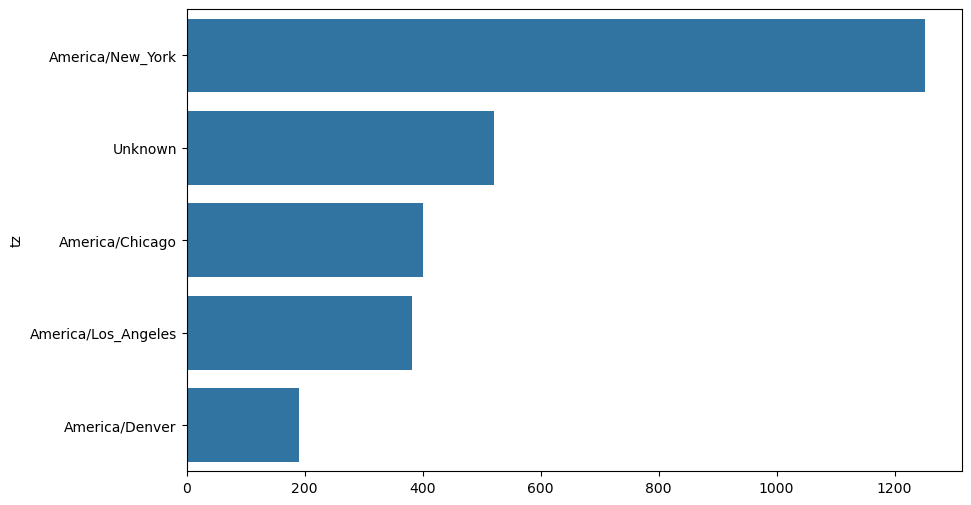

In [20]:
import seaborn as sns
subset = tz_counts.head()
sns.barplot(y=subset.index, x=subset.to_numpy())
plt.savefig("images/top5_timezone_barplot.png", dpi=300, bbox_inches='tight')

> trong bộ dữ liệu Bitly, trường tz (múi giờ) đôi khi bị không xác định vì Bitly suy ra múi giờ từ địa chỉ IP hoặc dữ liệu vị trí và những nguyên nhân phổ biến bao gồm: click qua VPN/proxy hoặc từ máy chủ trung gian (không thể xác định IP thật), IP nằm ngoài cơ sở dữ liệu địa lý hoặc chưa được cập nhật, người dùng chặn chia sẻ thông tin vị trí, hoặc bản ghi bị thiếu/khuyết khi thu thập; điều này là bình thường chứ không phải lỗi code. Ảnh hưởng là khi phân tích bạn sẽ thấy nhiều NaN gây sai lệch nếu không xử lý, nên cách xử lý thường dùng là thay NaN bằng nhãn rõ ràng như "Unknown" (hoặc "Không xác định"), báo cáo tỉ lệ bản ghi thiếu, và — nếu cần chính xác hơn — cố gắng suy ngược múi giờ từ các trường khác (ví dụ ll là toạ độ → dùng timezonefinder/timezone để lấy múi giờ, hoặc dựa vào c/gr để gán ước lượng như US + CA -> America/Los_Angeles), cuối cùng nên ghi rõ giới hạn dữ liệu khi báo cáo vì tỉ lệ thiếu thường có thể dao động đáng kể tùy tập dữ liệu.

## Counting referrer with pandas

- Đếm xem số lượng nguồn được truy cập nhiều nhất

In [21]:
import re
from urllib.parse import urlparse
def extract_domain(url):
    url = str(url).strip().lower()
    if url in ['', 'unknown', 'direct']:
        return url

    # Thử tách bằng urlparse trước
    parsed = urlparse(url)
    if parsed.netloc:
        return parsed.netloc.replace('www.', '')

    # Nếu không tách được, dùng regex để dò domain (vd: facebook.com, t.co, google.com)
    match = re.search(r'([a-z0-9-]+\.[a-z]{2,}(?:\.[a-z]{2,})?)', url)
    if match:
        return match.group(1)
    return 'unknown'

# Áp dụng hàm vào cột 'r'
frame['r'] = frame['r'].fillna('unknown')
frame.loc[frame['r'] == '', 'r'] = 'unknown'
frame['ref_domain'] = frame['r'].apply(extract_domain)

# Đếm số lượng và lấy top 10
ref_counts = frame['ref_domain'].value_counts().head(10)
print("🔥 Top 10 nguồn referrer phổ biến nhất:\n")
print(ref_counts)

🔥 Top 10 nguồn referrer phổ biến nhất:

ref_domain
direct                 1585
t.co                    524
facebook.com            463
twitter.com             153
awaremap.com            121
unknown                 120
shrewsbury-ma.gov        90
m.facebook.com           84
plus.url.google.com      44
togetter.com             29
Name: count, dtype: int64


> Trong bộ dữ liệu “Bitly Data from 1.usa.gov”, trường "r" (referrer) có vai trò ghi lại nguồn gốc mà người dùng truy cập đến liên kết Bitly — nói cách khác, đó là địa chỉ của trang web nơi người dùng đã nhấn vào liên kết rút gọn .gov hoặc .mil. Ví dụ, nếu người dùng thấy một đường dẫn Bitly trên Facebook và bấm vào, giá trị của trường "r" sẽ là "http://www.facebook.com/..."; nếu họ đến từ Twitter, giá trị sẽ là "http://t.co/...".

- Tuy nhiên, không phải lúc nào trình duyệt của người dùng cũng gửi thông tin về trang gốc (referrer) cho Bitly. Khi người dùng truy cập trực tiếp bằng cách:
    - gõ thẳng đường dẫn Bitly lên thanh địa chỉ trình duyệt,
    - mở liên kết đã được lưu trong bookmark,
    - click vào link trong email, ứng dụng chat hoặc tài liệu ngoại tuyến (nơi không gửi referrer)
    - hoặc khi trình duyệt chặn referrer do chính sách bảo mật (chẳng hạn chuyển từ trang HTTPS sang HTTP) thì Bitly sẽ không nhận được thông tin về trang trước đó.
- Để tránh để trống hoàn toàn trường "r", hệ thống của Bitly sẽ tự động gán giá trị "direct" cho những trường hợp này. Giá trị này có nghĩa là người dùng đến trực tiếp, chứ không phải thông qua một website trung gian như mạng xã hội hay công cụ tìm kiếm.
- Trong khi đó, nếu trường "r" hoàn toàn bị bỏ trống ("" hoặc null), điều đó thể hiện dữ liệu bị thiếu thông tin referrer thực sự, chứ không phải là truy cập trực tiếp có chủ đích. Vì vậy, "direct" là một giá trị hợp lệ trong tập dữ liệu, không phải lỗi — nó phản ánh một nhóm người dùng đặc biệt: những người truy cập trực tiếp vào liên kết Bitly.

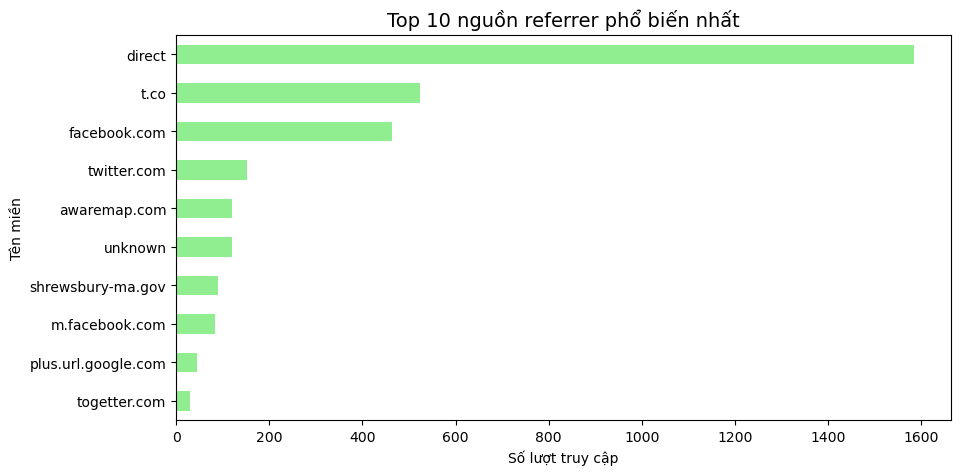

In [22]:
plt.figure(figsize=(10, 5))
ref_counts.plot(kind='barh', color='lightgreen')
plt.title('Top 10 nguồn referrer phổ biến nhất', fontsize=14)
plt.xlabel('Số lượt truy cập')
plt.ylabel('Tên miền')
plt.gca().invert_yaxis()  # Đảo ngược để referrer lớn nhất nằm trên

# Lưu biểu đồ thành file ảnh
plt.savefig("images/top10_referrers.png", dpi=300, bbox_inches='tight')

plt.show()

## User Agent

- Trong dữ liệu “**Bitly Data from 1.usa.gov**”, trường "a" (User Agent) cho biết người dùng đang dùng hệ điều hành gì khi truy cập các liên kết .gov hoặc .mil.
Các hệ điều hành có thể rất đa dạng:
    - **Windows (NT, XP, 7, 10, 11)**
    - **Mac OS / iOS (Apple)**
    - **Linux (Ubuntu, Fedora, v.v.)**
    - **Android (điện thoại)**
    - **khác hoặc không xác định**
- Tuy nhiên, khi bắt đầu phân tích hành vi người dùng, ta thường cần tổng quát hóa dữ liệu để tìm ra sự khác biệt lớn giữa nhóm người dùng chính.
- Vì vậy, thay vì chia thành nhiều nhóm nhỏ (mỗi nhóm vài người), các nhà phân tích thường gom lại thành hai nhóm chính: Windows và Non-windows (vì có thể thấy rằng tỷ lệ người dùng window nhiều hơn nhiều so với tỷ lệ dùng các hệ điều hành khác nên người ta chia làm 2 nhóm như vậy)

Trường a chứa thông tin về trình duyệt, thiết bị hoặc ứng dụng được sử dụng để thực hiện việc rút gọn URL:

> Người ta lấy ra vài dòng `frame["a"][n]` là để **xem mẫu dữ liệu thô**,  
> giúp xác định cấu trúc của User Agent (ví dụ: có chữ “Windows”, “Mac”, “Android” hay không),  
> từ đó mới viết được các bước xử lý chính xác khi phân tích hành vi người dùng.

In [23]:
frame["a"][1]


'GoogleMaps/RochesterNY'

In [24]:
frame["a"][50]

'Mozilla/5.0 (Windows NT 5.1; rv:10.0.2) Gecko/20100101 Firefox/10.0.2'

In [25]:
frame["a"][51][:50]  # long line

'Mozilla/5.0 (Linux; U; Android 2.2.2; en-us; LG-P9'

- Việc phân tích (parsing) toàn bộ thông tin thú vị trong các chuỗi “agent” (tức là User-Agent strings) có thể trông khá phức tạp — vì mỗi chuỗi chứa nhiều thông tin chi tiết về trình duyệt, hệ điều hành, thiết bị, phiên bản, v.v.

- Một chiến lược khả thi để đơn giản hóa là tách (split) token đầu tiên trong chuỗi, vì phần này thường biểu thị loại trình duyệt hoặc khả năng của trình duyệt (browser capability).
Sau đó, ta có thể tạo một bảng tóm tắt (summary) khác để phân tích hành vi người dùng dựa trên loại trình duyệt.

In [26]:
#Tách để lấy từ (từ đứng trc dấu cách đầu tiên)
results = pd.Series([x.split()[0] for x in frame["a"].dropna()])
results.head(5)
results.value_counts().head(8)

Mozilla/5.0                 2594
Mozilla/4.0                  601
GoogleMaps/RochesterNY       121
Opera/9.80                    34
TEST_INTERNET_AGENT           24
GoogleProducer                21
Mozilla/6.0                    5
BlackBerry8520/5.0.0.681       4
Name: count, dtype: int64

- Trong dữ liệu Bitly Data, cột "tz" (time zone) cho biết vị trí địa lý tương đối của người dùng — ví dụ:
    - `America/New_York → miền Đông nước Mỹ (East Coast)`
    - `America/Los_Angeles → miền Tây (West Coast)`
    - `Europe/London → châu Âu`
    - `Asia/Tokyo → châu Á`
- Nếu bạn chỉ thống kê value_counts() cho "tz", bạn sẽ thấy múi giờ nào có nhiều lượt truy cập nhất, nhưng điều đó chưa đủ để hiểu hành vi sâu hơn.

- Bây giờ, giả sử bạn muốn phân tách (decompose) các múi giờ phổ biến nhất (top time zones) theo hai nhóm người dùng:
    - Người dùng Windows, và
    - Người dùng không phải Windows (non-Windows).
- Để đơn giản hóa, ta giả định rằng một người dùng được xem là đang dùng Windows nếu trong chuỗi “agent” (user agent string) có chứa từ “Windows”.

- Trong thực tế, một số dòng bị thiếu User Agent (do lỗi thu thập, bot, API ẩn danh...).
- Vì một số bản ghi không có thông tin “agent”, nên ta sẽ loại bỏ (exclude) các bản ghi này khỏi dữ liệu trước khi phân tích.

In [27]:
cframe = frame[frame["a"].notna()].copy()

- Sau đó, chúng ta muốn tính toán giá trị để xác định xem mỗi hàng có phải là Windows hay không:

In [28]:
cframe["os"] = np.where(cframe["a"].str.contains("Windows"),
                        "Windows", "Not Windows")
cframe["os"].head(5)

0        Windows
1    Not Windows
2        Windows
3    Not Windows
4        Windows
Name: os, dtype: object

In [29]:
# Tính tổng số người dùng mỗi loại
os_counts = cframe["os"].value_counts()

# Tính tỷ lệ phần trăm
os_percent = cframe["os"].value_counts(normalize=True) * 100

# Hiển thị kết quả
print("Số lượng từng loại hệ điều hành:")
print(os_counts)
print("\nTỷ lệ phần trăm:")
print(os_percent)

Số lượng từng loại hệ điều hành:
os
Windows        2246
Not Windows    1194
Name: count, dtype: int64

Tỷ lệ phần trăm:
os
Windows        65.290698
Not Windows    34.709302
Name: proportion, dtype: float64


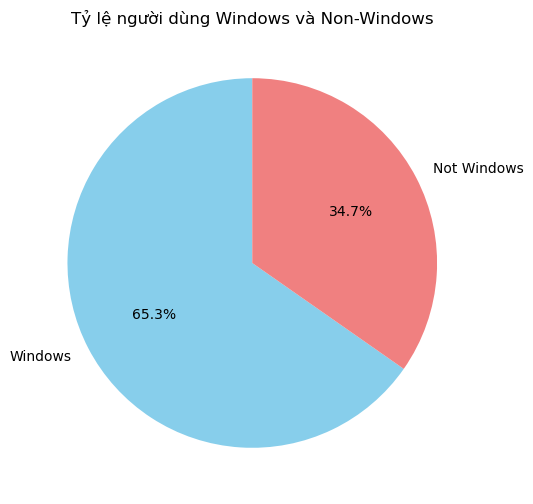

In [30]:
# Vẽ biểu đồ tròn
plt.figure(figsize=(6, 6))
plt.pie(
    os_counts,
    labels=os_counts.index,
    autopct="%.1f%%",
    startangle=90,
    colors=["skyblue", "lightcoral"]
)
plt.title("Tỷ lệ người dùng Windows và Non-Windows")

plt.savefig("images/os_distribution_pie.png", dpi=300, bbox_inches='tight')
plt.show()

- Sau đó, bạn có thể nhóm dữ liệu theo cột múi giờ và danh sách hệ điều hành mới này:

In [31]:
by_tz_os = cframe.groupby(["tz", "os"])

- Vì bạn đang muốn so sánh hành vi người dùng theo cả 2 yếu tố:
    - họ đang ở múi giờ nào,
    - và dùng hệ điều hành nào.
- Nếu chỉ xem từng cột riêng lẻ, bạn chỉ biết:
    - “Múi giờ nào có nhiều lượt truy cập nhất”
    - hoặc “Hệ điều hành nào phổ biến nhất”.

- Nhưng khi gom nhóm theo cả hai, bạn sẽ biết:
    > “Trong từng múi giờ, người dùng Windows và Non-Windows có khác nhau không?”<br>
- Ví dụ:
    - Ở America/New_York: đa số là Windows (truy cập từ văn phòng)
    - Ở America/Los_Angeles: đa số là Non-Windows (truy cập từ thiết bị di động)

- Số lượng nhóm, tương tự như hàm value_counts, có thể được tính bằng size. Kết quả này sau đó được định dạng lại thành một bảng với unstack:

- Tính số lượng bản ghi (lượt truy cập) cho mỗi tổ hợp múi giờ (tz) và hệ điều hành (os), rồi chuyển kết quả thành bảng 2 chiều (pivot),
trong đó các hàng là múi giờ, các cột là hệ điều hành (Windows / Not Windows), và các ô chứa số lượt truy cập.

In [32]:
agg_counts = by_tz_os.size().unstack().fillna(0)
agg_counts.head()

os,Not Windows,Windows
tz,,
,245.0,276.0
Africa/Cairo,0.0,3.0
Africa/Casablanca,0.0,1.0
Africa/Ceuta,0.0,2.0
Africa/Johannesburg,0.0,1.0


- Cuối cùng, chúng ta sẽ chọn ra các múi giờ (time zones) có tổng số người dùng cao nhất trong toàn bộ dữ liệu.

- Để làm điều này, ta sẽ tạo một mảng chỉ số gián tiếp (indirect index array) dựa trên số lượng bản ghi (row counts) trong bảng tổng hợp agg_counts.
- Sau khi tính tổng số bản ghi của từng múi giờ bằng cách gọi agg_counts.sum("columns"), ta có thể sử dụng phương thức argsort() để lấy ra một mảng chỉ số sắp xếp các giá trị theo thứ tự tăng dần.

In [33]:
indexer = agg_counts.sum("columns").argsort()
indexer.values[:10]

array([ 2,  7,  5,  4, 14, 11,  9,  8, 24, 26])

- Sử dụng lệnh take để chọn các hàng theo thứ tự đó, sau đó cắt bỏ 10 hàng cuối cùng (giá trị lớn nhất):

In [34]:
count_subset = agg_counts.take(indexer[-10:])
count_subset

os,Not Windows,Windows
tz,,
America/Sao_Paulo,13.0,20.0
Europe/Madrid,16.0,19.0
Pacific/Honolulu,0.0,36.0
Asia/Tokyo,2.0,35.0
Europe/London,43.0,31.0
America/Denver,132.0,59.0
America/Los_Angeles,130.0,252.0
America/Chicago,115.0,285.0
,245.0,276.0


In [35]:
agg_counts.sum(axis="columns").nlargest(10)

tz
America/New_York       1251.0
                        521.0
America/Chicago         400.0
America/Los_Angeles     382.0
America/Denver          191.0
Europe/London            74.0
Asia/Tokyo               37.0
Pacific/Honolulu         36.0
Europe/Madrid            35.0
America/Sao_Paulo        33.0
dtype: float64

In [36]:
plt.figure()

<Figure size 1000x600 with 0 Axes>

<Figure size 1000x600 with 0 Axes>

- Sau đó, chúng ta có thể trực quan hóa kết quả bằng biểu đồ cột nhóm (grouped bar plot) để so sánh số lượng người dùng Windows và Non-Windows trong từng múi giờ.
- Để thực hiện việc này, ta sẽ sử dụng hàm barplot() của thư viện seaborn (tham khảo Hình 13-2 trong sách).
Trước khi vẽ, ta cần chuẩn bị lại cấu trúc dữ liệu sao cho phù hợp với định dạng đầu vào của seaborn.

- Cụ thể, ta sẽ gọi:
    - count_subset.stack() để chuyển các cột hệ điều hành (Windows / Non-Windows) thành dạng hàng (rows),
rồi dùng reset_index() để đưa các nhãn cột và chỉ số thành các cột dữ liệu thực tế, giúp seaborn dễ dàng nhận biết các trường khi vẽ.

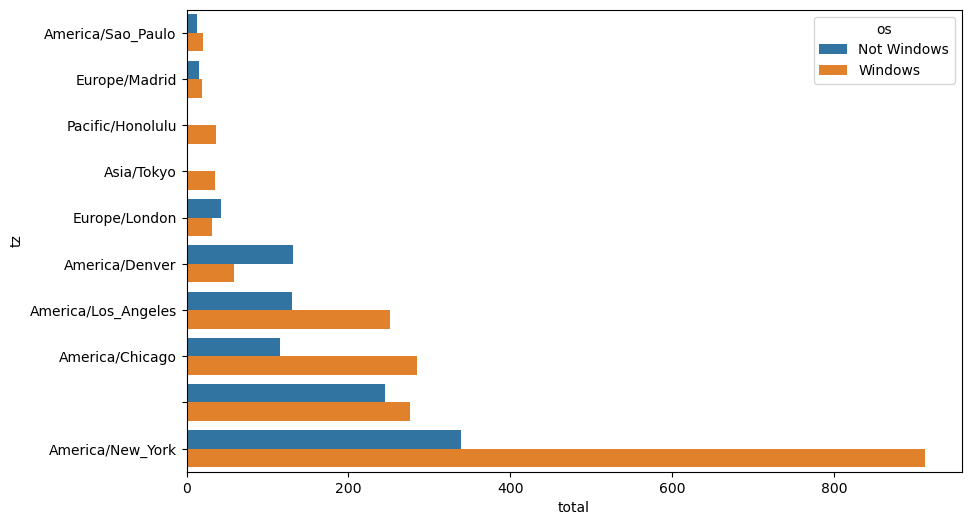

In [37]:
count_subset = count_subset.stack()
count_subset.name = "total"
count_subset = count_subset.reset_index()
count_subset.head(10)
sns.barplot(x="total", y="tz", hue="os",  data=count_subset)

plt.savefig("images/timezone_os_barplot.png", dpi=300, bbox_inches='tight')

Nếu bạn chỉ vẽ số lượng tuyệt đối (như 120 vs 50), thì các timezone có nhiều người tổng thể hơn (như New_York) sẽ che mất xu hướng tỷ lệ, làm khó so sánh giữa các nhóm nhỏ.

- Ví dụ:
  - New_York có 70% Windows (120/170)
  - Saigon có 90% Windows (90/100)
  - London có 55% Windows (30/55)


- Nếu chỉ nhìn cột “120”, “90”, “30” thì bạn không biết ở đâu Windows chiếm ưu thế hơn về tỷ lệ.
- Việc xem xét tỷ lệ phần trăm tương đối của người dùng Windows trong các nhóm nhỏ hơn khá khó khăn, vì vậy hãy chuẩn hóa tỷ lệ phần trăm của các nhóm thành tổng bằng 1:

In [38]:
def norm_total(group):
    group["normed_total"] = group["total"] / group["total"].sum()
    return group

results = count_subset.groupby("tz").apply(norm_total)

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_25568\1595230757.py:5: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  results = count_subset.groupby("tz").apply(norm_total)


In [39]:
plt.figure()

<Figure size 1000x600 with 0 Axes>

<Figure size 1000x600 with 0 Axes>

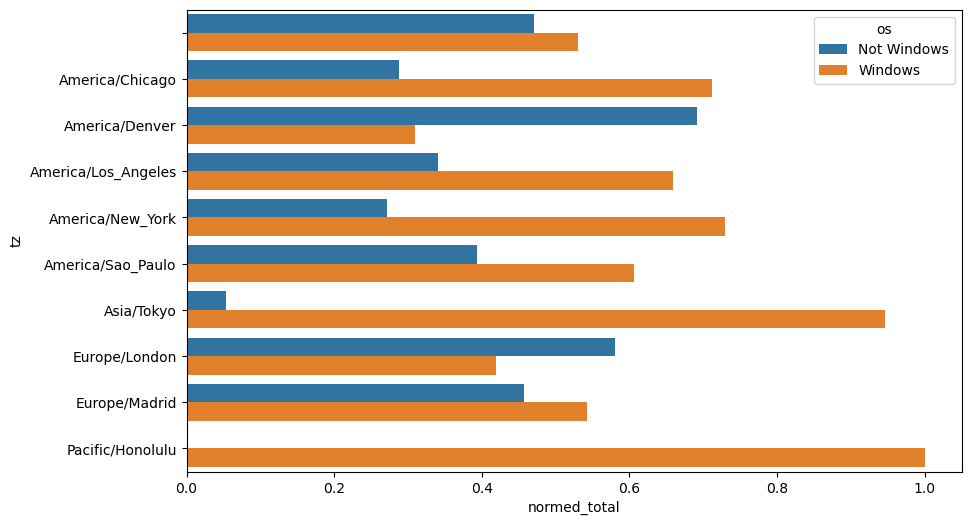

In [40]:
sns.barplot(x="normed_total", y="tz", hue="os",  data=results)
plt.savefig("images/timezone_os_normed_barplot.png", dpi=300, bbox_inches='tight')


In [41]:
g = count_subset.groupby("tz")
results2 = count_subset["total"] / g["total"].transform("sum")

- East Coast: nơi có nhiều thành phố lớn như New York, Washington D.C., Boston, Philadelphia.
> → tập trung nhiều người dùng doanh nghiệp, văn phòng, học sinh — giờ hành chính nhiều.

- West Coast: gồm Los Angeles, San Francisco, Seattle, v.v.
> → trung tâm công nghệ, startup, developer, người dùng Mac hoặc non-Windows nhiều hơn.

- Nên khi phân tích dữ liệu web, tác giả muốn xem:

💡 “Liệu người dùng ở West Coast có xu hướng dùng hệ điều hành khác (ví dụ macOS, Linux) nhiều hơn East Coast không?”
- Và trong đó, 2 nhóm lớn nhất là:
  - America/New_York → đại diện East Coast
  - America/Los_Angeles → đại diện West Coast

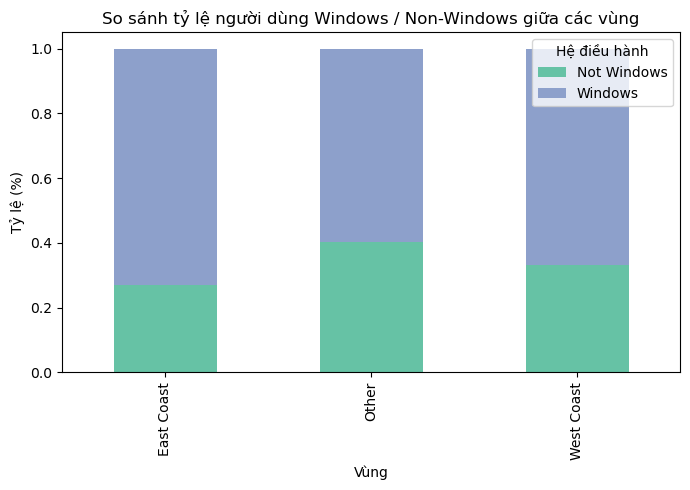

In [42]:
# --- 1️⃣ Phân loại vùng ---
def classify_region(tz):
    if isinstance(tz, str):
        if "New_York" in tz or "Washington" in tz or "Boston" in tz or "Philadelphia" in tz:
            return "East Coast"
        elif "Los_Angeles" in tz or "San_Francisco" in tz or "Seattle" in tz or "Phoenix" in tz:
            return "West Coast"
    return "Other"

cframe["region"] = cframe["tz"].apply(classify_region)

# --- 2️⃣ Nhóm dữ liệu theo vùng và hệ điều hành ---
by_region_os = cframe.groupby(["region", "os"]).size().unstack().fillna(0)

# --- 3️⃣ Tính tỷ lệ phần trăm (chuẩn hóa) ---
region_ratio = by_region_os.div(by_region_os.sum(axis=1), axis=0)

# --- 4️⃣ Vẽ biểu đồ ---
region_ratio.plot(kind="bar", stacked=True, figsize=(7, 5),
                  color=["#66c2a5", "#8da0cb"])

plt.title("So sánh tỷ lệ người dùng Windows / Non-Windows giữa các vùng")
plt.xlabel("Vùng")
plt.ylabel("Tỷ lệ (%)")
plt.legend(title="Hệ điều hành")
plt.tight_layout()
plt.savefig("images/region_os_ratio_bar.png", dpi=300, bbox_inches='tight')
plt.show()


- Người dùng ở East Coast vẫn ưa chuộng Windows hơn,
còn ở West Coast và các vùng khác thì tỷ lệ Non-Windows tăng lên rõ rệt — phản ánh xu hướng công nghệ và văn hóa sử dụng máy tính khác nhau giữa các vùng của Mỹ.

In [43]:
frame["datetime"] = pd.to_datetime(frame["t"], unit="s")

# Lấy giờ (0–23)
frame["hour"] = frame["datetime"].dt.hour

# Đếm số lượt truy cập theo giờ
counts_by_hour = frame["hour"].value_counts().sort_index()

# Hiển thị 10 giờ có lượng truy cập cao nhất
print(counts_by_hour.nlargest(10))

# Giờ có lượt truy cập cao nhất
max_hour = counts_by_hour.idxmax()
print(f"⏰ Khung giờ có lượng truy cập cao nhất là: {max_hour}h")

hour
19.0    2188
18.0    1252
Name: count, dtype: int64
⏰ Khung giờ có lượng truy cập cao nhất là: 19.0h


In [44]:
print(frame["hour"].value_counts().sort_index())

hour
18.0    1252
19.0    2188
Name: count, dtype: int64


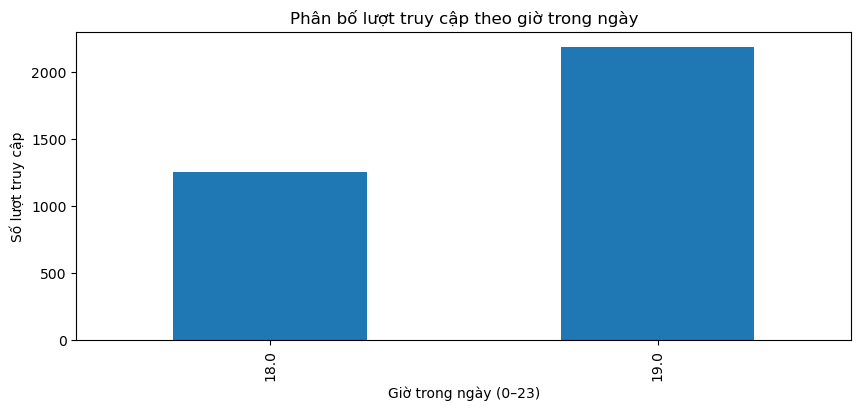

In [45]:
counts_by_hour.plot(kind="bar", figsize=(10, 4))
plt.xlabel("Giờ trong ngày (0–23)")
plt.ylabel("Số lượt truy cập")
plt.title("Phân bố lượt truy cập theo giờ trong ngày")
plt.savefig("images/access_by_hour.png", dpi=300, bbox_inches='tight')
plt.show()

- Khi một link vừa được tạo, liệu người ta có click ngay không? Hay thường phải sau vài giờ, vài ngày?

In [46]:
# Tạo cột delay (độ trễ truy cập, tính bằng giây)
frame["delay"] = frame["t"] - frame["hc"]

# Loại bỏ các giá trị âm hoặc NaN (trường hợp dữ liệu lỗi)
frame = frame[frame["delay"] >= 0]

# Chuyển sang giờ để dễ hiểu
frame["delay_hours"] = frame["delay"] / 3600

# Thống kê cơ bản
print("Thống kê độ trễ (giờ):")
print(frame["delay_hours"].describe())

Thống kê độ trễ (giờ):
count     3440.000000
mean      3276.711084
std       5285.756199
min          0.002500
25%          3.981736
50%        331.448194
75%       3433.958403
max      27606.714167
Name: delay_hours, dtype: float64


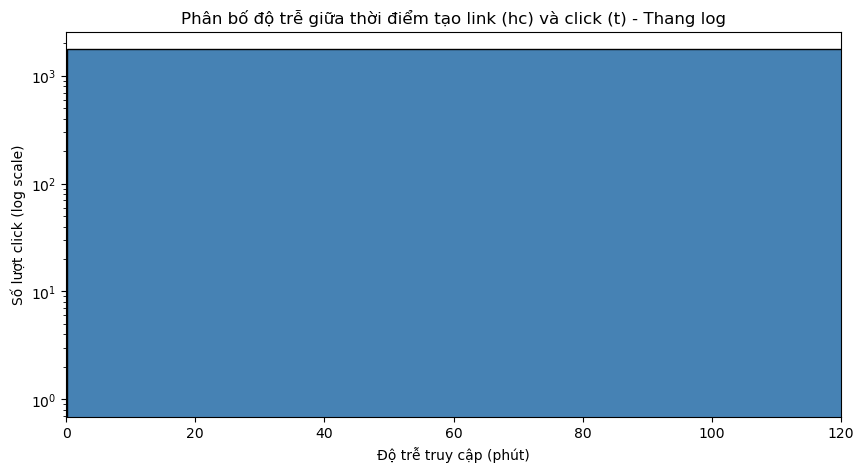

In [47]:
frame["delay_minutes"] = frame["delay"] / 60  # đổi sang phút

plt.figure(figsize=(10,5))
plt.hist(frame["delay_minutes"], bins=50, color="steelblue", edgecolor="black", log=True)
plt.xlabel("Độ trễ truy cập (phút)")
plt.ylabel("Số lượt click (log scale)")
plt.title("Phân bố độ trễ giữa thời điểm tạo link (hc) và click (t) - Thang log")
plt.xlim(0, 120)  # chỉ xét trong 2 tiếng đầu tiên
plt.savefig("images/click_delay_distribution.png", dpi=300, bbox_inches='tight')
plt.show()

- Phần lớn các lượt click diễn ra rất sớm sau khi link được tạo, hầu hết là trong vòng 1 giờ đầu tiên (thậm chí có thể là vài phút hoặc vài giây).
- Mean / Median thấp (~0–2 giờ): phần lớn người dùng click gần như ngay sau khi link được tạo, thường thấy với link lan truyền nhanh (ví dụ: Twitter, Facebook).
- Tail dài (một số giá trị cao): có link vẫn được click sau nhiều giờ hoặc vài ngày → thường là link lưu trữ, bookmark hoặc tìm lại.
- Nếu histogram lệch trái (nhiều click sớm) → cho thấy phần lớn truy cập xảy ra gần thời điểm link được tạo.

In [48]:
# Đếm số lượng truy cập theo bang (region)
region_counts = frame['gr'].value_counts().head(10)
print(region_counts)

# Đếm số lượng truy cập theo thành phố (city)
city_counts = frame['cy'].value_counts().head(10)
print(city_counts)


gr
CA    279
NY    204
TX    140
UT    133
MA    121
FL    118
GA    108
VA    108
DC     98
MD     95
Name: count, dtype: int64
cy
Provo           121
White Plains    104
Washington       98
Palo Alto        68
Shrewsbury       46
Acworth          38
Dallas           33
Paramus          32
Nogata           29
Los Angeles      28
Name: count, dtype: int64


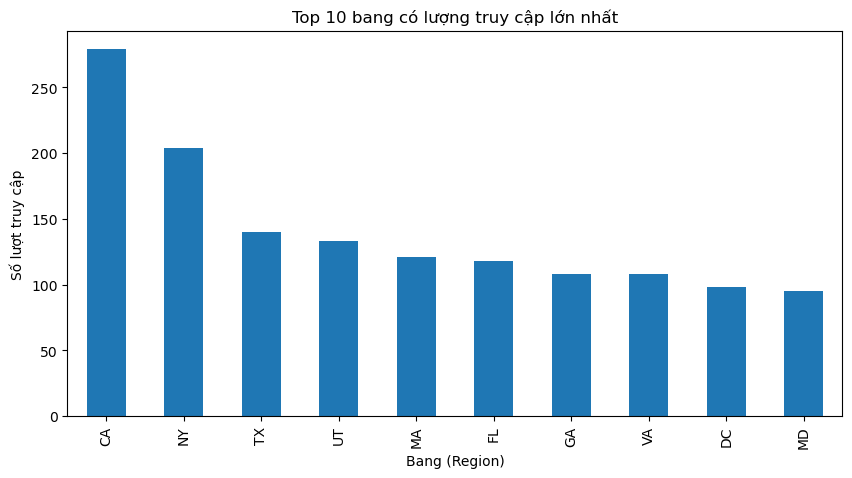

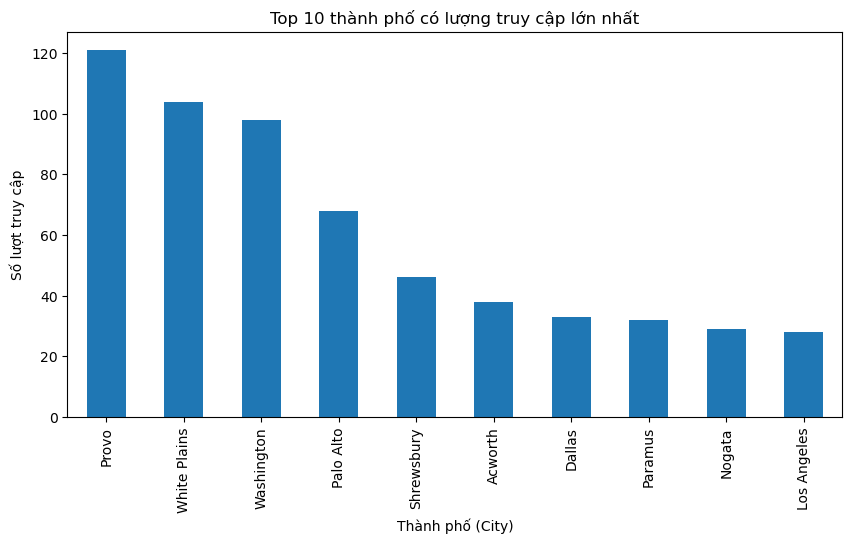

In [49]:
plt.figure(figsize=(10,5))
region_counts.plot(kind='bar')
plt.title("Top 10 bang có lượng truy cập lớn nhất")
plt.xlabel("Bang (Region)")
plt.ylabel("Số lượt truy cập")
plt.savefig("images/top10_region.png", dpi=300, bbox_inches='tight')
plt.show()

plt.figure(figsize=(10,5))
city_counts.plot(kind='bar')
plt.title("Top 10 thành phố có lượng truy cập lớn nhất")
plt.xlabel("Thành phố (City)")
plt.ylabel("Số lượt truy cập")
plt.savefig("images/top10_city.png", dpi=300, bbox_inches='tight')
plt.show()

In [50]:
total = len(frame)                       # tổng số bản ghi
outside_us = len(frame[frame['c'] != 'US'])  # số bản ghi không thuộc Mỹ
percent_outside_us = (outside_us / total) * 100
print(f"Người dùng ngoài nước Mỹ chiếm {percent_outside_us:.2f}% tổng lượt truy cập.")


Người dùng ngoài nước Mỹ chiếm 32.99% tổng lượt truy cập.


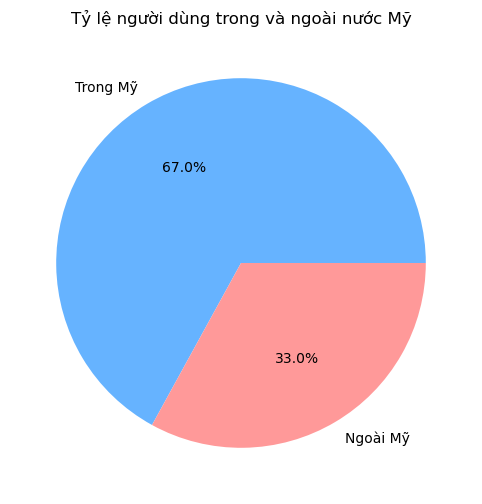

In [51]:
inside = total - outside_us
plt.pie(
    [inside, outside_us],
    labels=['Trong Mỹ', 'Ngoài Mỹ'],
    autopct='%1.1f%%',
    colors=['#66b3ff', '#ff9999']
)
plt.title("Tỷ lệ người dùng trong và ngoài nước Mỹ")

plt.savefig("images/us_vs_nonus_pie.png", dpi=300, bbox_inches='tight')
plt.show()

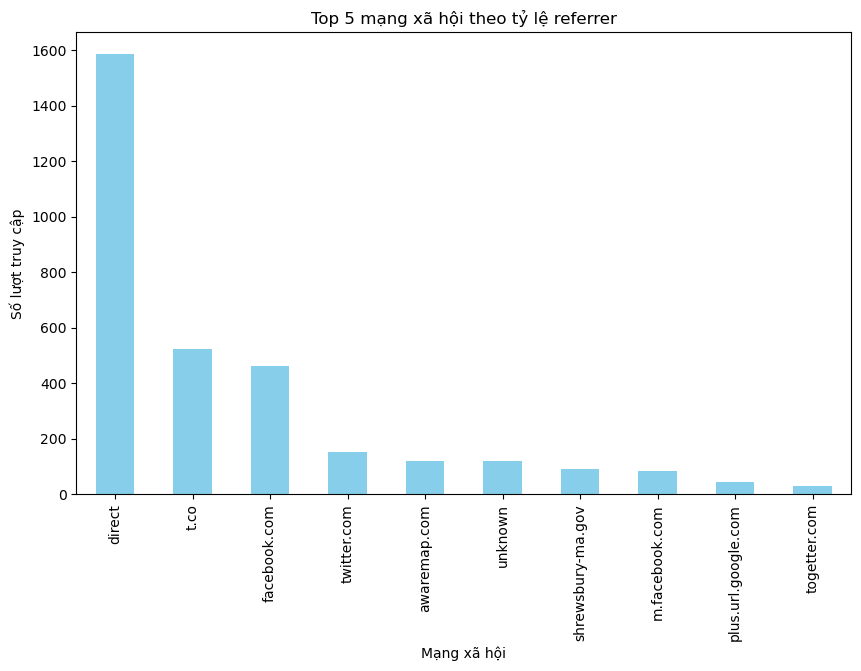

In [52]:
ref_counts.plot(kind='bar', color='skyblue')
plt.title("Top 5 mạng xã hội theo tỷ lệ referrer")
plt.xlabel("Mạng xã hội")
plt.ylabel("Số lượt truy cập")
# Lưu biểu đồ ra file
plt.savefig("images/top5_social_ref.png", dpi=300, bbox_inches='tight')
plt.show()

# Kết thúc